# Giai đoạn 5a: Huấn luyện & Đánh giá các mô hình Machine Learning truyền thống (ML Baselines)

Đánh giá **4 thí nghiệm ML truyền thống** trên bộ dữ liệu đa nguồn (**`20.852` mẫu, `35` nhãn chuẩn**; `train=14.613`, `val=3.125`, `test=3.114`):
1. `TN0_naive_baseline`: Naive Majority Baseline (tham chiếu nhãn phổ biến).
2. `TN1_nb_bow`: Multinomial Naive Bayes (Bag-of-Words `10.000` chiều).
3. `TN2_multinomial_nb`: Multinomial Naive Bayes (TF-IDF `10.000` chiều).
4. `TN3_linear_svm`: Linear SVM (`LinearSVC`, TF-IDF `10.000` chiều, `class_weight="balanced"`).
5. `TN4_logistic_regression`: Logistic Regression (TF-IDF `10.000` chiều, `class_weight="balanced"`).

Kèm phân tích cặp nhãn nhầm lẫn `35×35`, trích xuất 12 mẫu lỗi tiêu biểu và giải thích mô hình thông qua top-8 từ khóa trọng số `coef_`.

In [1]:
import json
import sys
import time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import joblib
import numpy as np
import pandas as pd

from src.config import (
    EXPERIMENTS_CSV,
    FIGURES_DIR,
    GENRE_DISPLAY_NAMES,
    GENRE_LABELS,
    MODELS_DIR,
    RANDOM_STATE,
    STORIES_CLEAN_CSV,
    TFIDF_VECTORIZER_PATH,
)
from src.features.bow_tfidf import build_bow_vectorizer, load_tfidf_vectorizer
from src.models.ml_models import (
    apply_thresholds,
    get_linear_svm,
    get_logistic_regression,
    get_naive_bayes,
    predict_probabilities,
    save_model,
    tune_per_label_thresholds,
)
from src.evaluation.metrics import (
    evaluate_model,
    plot_f1_per_label,
    plot_model_comparison,
    plot_multilabel_confusion_matrices,
    save_experiment_result,
)

df = pd.read_csv(STORIES_CLEAN_CSV, encoding="utf-8")
label_cols = [f"label_{g}" for g in GENRE_LABELS]

print(f"Tổng số mẫu: {len(df)} | Số cột: {len(df.columns)}")
print("Số giá trị thiếu ở tokens:", int(df["tokens"].isna().sum()))
print("Số giá trị thiếu ở nhãn  :", int(df[label_cols].isna().sum().sum()))
print("\nPhân bố tập dữ liệu:")
print(df["split"].value_counts())

train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

y_train = train_df[label_cols].to_numpy(dtype=int)
y_val = val_df[label_cols].to_numpy(dtype=int)
y_test = test_df[label_cols].to_numpy(dtype=int)

# Nạp TF-IDF vectorizer đã fit trên train (dùng chung cho toàn bộ mô hình)
tfidf_vec = load_tfidf_vectorizer(TFIDF_VECTORIZER_PATH)
x_train_tfidf = tfidf_vec.transform(train_df["tokens"].fillna(""))
x_val_tfidf = tfidf_vec.transform(val_df["tokens"].fillna(""))
x_test_tfidf = tfidf_vec.transform(test_df["tokens"].fillna(""))

# Fit Bag-of-Words vectorizer chỉ trên tập train cho thí nghiệm TN1
bow_vec = build_bow_vectorizer()
x_train_bow = bow_vec.fit_transform(train_df["tokens"].fillna(""))
x_val_bow = bow_vec.transform(val_df["tokens"].fillna(""))
x_test_bow = bow_vec.transform(test_df["tokens"].fillna(""))
joblib.dump(bow_vec, MODELS_DIR / "bow_vectorizer.pkl")

print(f"\nKích thước ma trận TF-IDF: train={x_train_tfidf.shape}, val={x_val_tfidf.shape}, test={x_test_tfidf.shape}")
print(f"Kích thước ma trận BoW   : train={x_train_bow.shape}, val={x_val_bow.shape}, test={x_test_bow.shape}")

Tổng số mẫu: 20852 | Số cột: 52
Số giá trị thiếu ở tokens: 1
Số giá trị thiếu ở nhãn  : 0

Phân bố tập dữ liệu:
split
train    14613
val       3125
test      3114
Name: count, dtype: int64



Kích thước ma trận TF-IDF: train=(14613, 10000), val=(3125, 10000), test=(3114, 10000)
Kích thước ma trận BoW   : train=(14613, 10000), val=(3125, 10000), test=(3114, 10000)


### Phân tích dữ liệu & đặc trưng đầu vào
- Bộ dữ liệu `stories_clean.csv` gồm **20.852 mẫu (`35` nhãn)**, chia phân tầng thành `train = 14.613`, `val = 3.125`, `test = 3.114` trên không gian **TF-IDF / BoW `10.000` chiều** (`1` mẫu `ST_12713` trong `train` rỗng `tokens` sau cắt header `"Thể loại:"`, `val` và `test` có `0` giá trị thiếu).

In [2]:
# Naive Baseline: dự đoán theo tần suất nhãn trên tập train (ngưỡng 0.5, giữ tối thiểu nhãn top-1)
train_label_freq = y_train.mean(axis=0)
naive_val_probs = np.tile(train_label_freq, (len(y_val), 1))
naive_val_preds = apply_thresholds(naive_val_probs, thresholds=0.5, ensure_non_empty=True)
naive_val_metrics = evaluate_model(y_val, naive_val_preds, label_names=GENRE_LABELS)

baseline_configs = [
    ("TN1_nb_bow", "Multinomial NB (BoW)", "BoW (1-2 gram)", get_naive_bayes(), x_train_bow, x_val_bow),
    ("TN2_multinomial_nb", "Multinomial NB (TF-IDF)", "TF-IDF (1-2 gram)", get_naive_bayes(), x_train_tfidf, x_val_tfidf),
    ("TN3_linear_svm", "Linear SVM (TF-IDF)", "TF-IDF (1-2 gram)", get_linear_svm(), x_train_tfidf, x_val_tfidf),
    ("TN4_logistic_regression", "Logistic Regression (TF-IDF)", "TF-IDF (1-2 gram)", get_logistic_regression(), x_train_tfidf, x_val_tfidf),
]

baseline_rows = [
    {
        "experiment_id": "TN0_naive_baseline",
        "model": "Naive Majority Baseline",
        "train_macro_f1": np.nan,
        "val_accuracy": naive_val_metrics["accuracy"],
        "val_macro_f1": naive_val_metrics["macro_f1"],
        "val_micro_f1": naive_val_metrics["micro_f1"],
        "val_hamming_loss": naive_val_metrics["hamming_loss"],
        "train_time_s": 0.0,
        "val_infer_ms": 0.0,
    }
]

for exp_id, name, feat_name, model, x_tr, x_va in baseline_configs:
    t0 = time.perf_counter()
    model.fit(x_tr, y_train)
    train_time = time.perf_counter() - t0

    tr_probs = predict_probabilities(model, x_tr)
    tr_preds = apply_thresholds(tr_probs, thresholds=0.5, ensure_non_empty=True)
    tr_metrics = evaluate_model(y_train, tr_preds, label_names=GENRE_LABELS)

    t1 = time.perf_counter()
    va_probs = predict_probabilities(model, x_va)
    va_preds = apply_thresholds(va_probs, thresholds=0.5, ensure_non_empty=True)
    infer_ms = (time.perf_counter() - t1) * 1000.0
    va_metrics = evaluate_model(y_val, va_preds, label_names=GENRE_LABELS)

    baseline_rows.append(
        {
            "experiment_id": exp_id,
            "model": name,
            "train_macro_f1": tr_metrics["macro_f1"],
            "val_accuracy": va_metrics["accuracy"],
            "val_macro_f1": va_metrics["macro_f1"],
            "val_micro_f1": va_metrics["micro_f1"],
            "val_hamming_loss": va_metrics["hamming_loss"],
            "train_time_s": round(train_time, 3),
            "val_infer_ms": round(infer_ms, 2),
        }
    )

baseline_df = pd.DataFrame(baseline_rows)
display(baseline_df)

,experiment_id,model,train_macro_f1,val_accuracy,val_macro_f1,val_micro_f1,val_hamming_loss,train_time_s,val_infer_ms
0,TN0_naive_baseline,Naive Majority Baseline,NaN,0.0000,0.0203,0.2641,0.0877,0.000,0.00
1,TN1_nb_bow,Multinomial NB (BoW),0.4919,0.0250,0.3341,0.4773,0.1231,0.519,169.27
2,TN2_multinomial_nb,Multinomial NB (TF-IDF),0.1583,0.0563,0.1113,0.4122,0.0754,0.647,90.89
3,TN3_linear_svm,Linear SVM (TF-IDF),0.8994,0.0688,0.2840,0.4915,0.0745,17.356,45.05
4,TN4_logistic_regression,Logistic Regression (TF-IDF),0.2385,0.0685,0.1644,0.4454,0.0724,7.842,105.89


### Nhận xét kết quả Baseline mặc định (Train vs Validation)
- **`TN3_linear_svm` (C=1.0 mặc định):** Overfit khá rõ (`train_macro_f1 = 0.8994` vs `val_macro_f1 = 0.2840`).
- **`TN2_multinomial_nb` (alpha=1.0) & `TN4_logistic_regression` (C=1.0):** Ở ngưỡng `0.5` mặc định, xác suất đầu ra bị lệch thấp với các nhãn hiếm nên `val_macro_f1` mới đạt `0.1113` (`NB TF-IDF`) và `0.1644` (`LogReg`), cần tinh chỉnh regularization + tối ưu ngưỡng trên tập `val`.

In [3]:
# Tinh chỉnh siêu tham số trên tập val (chọn cấu hình có val_macro_f1 cao nhất)
tuning_logs = []
best_models = {}

def _tune_grid(exp_id, model_key, display_name, feat_name, candidates, x_tr, x_va, x_te):
    best_score = -1.0
    best_entry = None
    for params_desc, model in candidates:
        t0 = time.perf_counter()
        model.fit(x_tr, y_train)
        train_s = time.perf_counter() - t0
        va_probs = predict_probabilities(model, x_va)
        va_preds = apply_thresholds(va_probs, thresholds=0.5, ensure_non_empty=True)
        va_metrics = evaluate_model(y_val, va_preds, label_names=GENRE_LABELS)
        tuning_logs.append(
            {
                "experiment_id": exp_id,
                "model": display_name,
                "params": params_desc,
                "val_accuracy": va_metrics["accuracy"],
                "val_macro_f1": va_metrics["macro_f1"],
                "val_micro_f1": va_metrics["micro_f1"],
                "val_hamming_loss": va_metrics["hamming_loss"],
                "train_s": round(train_s, 3),
            }
        )
        if va_metrics["macro_f1"] > best_score:
            best_score = va_metrics["macro_f1"]
            best_entry = {
                "exp_id": exp_id,
                "key": model_key,
                "name": display_name,
                "feature_type": feat_name,
                "params": params_desc,
                "model": model,
                "val_probs": va_probs,
                "val_metrics_default": va_metrics,
                "x_test": x_te,
                "train_s": round(train_s, 3),
            }
    save_model(best_entry["model"], model_key, models_dir=MODELS_DIR)
    return best_entry

nb_alphas = [0.05, 0.1, 0.25, 0.5, 1.0]
best_models["nb_bow"] = _tune_grid(
    "TN1_nb_bow",
    "nb_bow",
    "Multinomial NB (BoW)",
    "BoW (1-2 gram)",
    [(f"alpha={a}", get_naive_bayes(alpha=a)) for a in nb_alphas],
    x_train_bow, x_val_bow, x_test_bow,
)
best_models["multinomial_nb"] = _tune_grid(
    "TN2_multinomial_nb",
    "multinomial_nb",
    "Multinomial NB (TF-IDF)",
    "TF-IDF (1-2 gram)",
    [(f"alpha={a}", get_naive_bayes(alpha=a)) for a in nb_alphas],
    x_train_tfidf, x_val_tfidf, x_test_tfidf,
)
best_models["linear_svm"] = _tune_grid(
    "TN3_linear_svm",
    "linear_svm",
    "Linear SVM (TF-IDF)",
    "TF-IDF (1-2 gram)",
    [(f"C={c}, cw={cw}", get_linear_svm(c=c, class_weight=cw)) for c in [0.25, 0.5, 1.0, 2.0] for cw in [None, "balanced"]],
    x_train_tfidf, x_val_tfidf, x_test_tfidf,
)
best_models["logistic_regression"] = _tune_grid(
    "TN4_logistic_regression",
    "logistic_regression",
    "Logistic Regression (TF-IDF)",
    "TF-IDF (1-2 gram)",
    [(f"C={c}, cw={cw}", get_logistic_regression(c=c, class_weight=cw)) for c in [0.5, 1.0, 2.0, 5.0, 10.0] for cw in [None, "balanced"]],
    x_train_tfidf, x_val_tfidf, x_test_tfidf,
)

tuning_df = pd.DataFrame(tuning_logs)
best_summary_df = pd.DataFrame(
    [
        {
            "experiment_id": entry["exp_id"],
            "model": entry["name"],
            "best_params": entry["params"],
            "val_accuracy": entry["val_metrics_default"]["accuracy"],
            "val_macro_f1": entry["val_metrics_default"]["macro_f1"],
            "val_micro_f1": entry["val_metrics_default"]["micro_f1"],
            "val_hamming_loss": entry["val_metrics_default"]["hamming_loss"],
        }
        for entry in best_models.values()
    ]
)
print("=== CẤU HÌNH TỐT NHẤT SAU TINH CHỈNH TRÊN VAL ===")
display(best_summary_df)

=== CẤU HÌNH TỐT NHẤT SAU TINH CHỈNH TRÊN VAL ===


,experiment_id,model,best_params,val_accuracy,val_macro_f1,val_micro_f1,val_hamming_loss
0,TN1_nb_bow,Multinomial NB (BoW),alpha=0.25,0.0256,0.3389,0.4804,0.1199
1,TN2_multinomial_nb,Multinomial NB (TF-IDF),alpha=0.05,0.0678,0.2117,0.4637,0.0740
2,TN3_linear_svm,Linear SVM (TF-IDF),"C=0.25, cw=balanced",0.0336,0.3747,0.5141,0.0989
3,TN4_logistic_regression,Logistic Regression (TF-IDF),"C=2.0, cw=balanced",0.0282,0.3796,0.5159,0.1003


### Phân tích kết quả tinh chỉnh siêu tham số
- Sau tinh chỉnh trên `val`: `TN1_nb_bow` chọn `alpha=0.25` (`val_macro_f1 = 0.3389`), `TN2_multinomial_nb` chọn `alpha=0.05` (`0.2117`), `TN3_linear_svm` chọn `C=0.25, cw=balanced` (`0.3747`), và `TN4_logistic_regression` chọn `C=2.0, cw=balanced` (`0.3796`).

In [4]:
# Tối ưu ngưỡng quyết định theo từng nhãn trên tập val
threshold_rows = []
saved_thresholds = {}

for key, entry in best_models.items():
    opt_thresh = tune_per_label_thresholds(y_val, entry["val_probs"])
    entry["opt_thresholds"] = opt_thresh
    saved_thresholds[key] = {
        lbl: round(float(opt_thresh[i]), 2) for i, lbl in enumerate(GENRE_LABELS)
    }
    val_preds_opt = apply_thresholds(entry["val_probs"], thresholds=opt_thresh, ensure_non_empty=True)
    val_metrics_opt = evaluate_model(y_val, val_preds_opt, label_names=GENRE_LABELS)
    entry["val_metrics_tuned"] = val_metrics_opt
    threshold_rows.append(
        {
            "model": entry["name"],
            "val_macro_f1_0.5": entry["val_metrics_default"]["macro_f1"],
            "val_macro_f1_tuned": val_metrics_opt["macro_f1"],
            "val_micro_f1_0.5": entry["val_metrics_default"]["micro_f1"],
            "val_micro_f1_tuned": val_metrics_opt["micro_f1"],
            "val_hamming_0.5": entry["val_metrics_default"]["hamming_loss"],
            "val_hamming_tuned": val_metrics_opt["hamming_loss"],
        }
    )

thresh_path = MODELS_DIR / "ml_thresholds.json"
thresh_path.write_text(json.dumps(saved_thresholds, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Đã lưu ngưỡng tối ưu theo từng nhãn tại: {thresh_path}")
display(pd.DataFrame(threshold_rows))
print("\nNgưỡng tối ưu theo từng nhãn (các mô hình):")
display(pd.DataFrame(saved_thresholds))

Đã lưu ngưỡng tối ưu theo từng nhãn tại: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\models\ml_thresholds.json


,model,val_macro_f1_0.5,val_macro_f1_tuned,val_micro_f1_0.5,val_micro_f1_tuned,val_hamming_0.5,val_hamming_tuned
0,Multinomial NB (BoW),0.3389,0.3516,0.4804,0.4931,0.1199,0.1177
1,Multinomial NB (TF-IDF),0.2117,0.3393,0.4637,0.5394,0.0740,0.0942
2,Linear SVM (TF-IDF),0.3747,0.3981,0.5141,0.5274,0.0989,0.1042
3,Logistic Regression (TF-IDF),0.3796,0.4115,0.5159,0.5451,0.1003,0.0999



Ngưỡng tối ưu theo từng nhãn (các mô hình):


,nb_bow,multinomial_nb,linear_svm,logistic_regression
ngon_tinh,0.15,0.25,0.40,0.25
dam_my,0.75,0.25,0.55,0.55
bach_hop,0.35,0.15,0.55,0.70
tong_tai,0.15,0.15,0.50,0.55
nu_phu,0.75,0.40,0.55,0.80
nu_cuong,0.65,0.20,0.50,0.50
sung,0.15,0.15,0.45,0.40
nguoc,0.20,0.15,0.45,0.40
hai_huoc,0.40,0.15,0.50,0.45
tien_hiep,0.70,0.20,0.50,0.55


### Phân tích tối ưu ngưỡng quyết định theo từng nhãn
- Tối ưu ngưỡng trên `val` (lưới `0.15`–`0.85`) cải thiện mạnh đồng loạt tất cả mô hình:
  - `Logistic Regression`: `val_macro_f1` tăng `0.3796 -> 0.4115`, `val_micro_f1` tăng `0.5159 -> 0.5451`.
  - `Linear SVM`: `val_macro_f1` tăng `0.3747 -> 0.3981`, `val_micro_f1` tăng `0.5141 -> 0.5274`.
  - `Multinomial NB (TF-IDF)`: `val_macro_f1` tăng `0.2117 -> 0.3393`, `val_micro_f1` tăng `0.4637 -> 0.5394`.
  - `Multinomial NB (BoW)`: `val_macro_f1` tăng `0.3389 -> 0.3516`, `val_micro_f1` tăng `0.4804 -> 0.4931`.

In [5]:
# Đánh giá cuối cùng trên tập TEST (chạy duy nhất 1 lần) & ghi experiments.csv
naive_test_probs = np.tile(train_label_freq, (len(y_test), 1))
naive_test_preds = apply_thresholds(naive_test_probs, thresholds=0.5, ensure_non_empty=True)
naive_test_metrics = evaluate_model(y_test, naive_test_preds, label_names=GENRE_LABELS)

test_comparison_rows = [
    {
        "experiment_id": "TN0_naive_baseline",
        "model_name": "Naive Majority Baseline",
        "feature_type": "Label Prior",
        "accuracy": naive_test_metrics["accuracy"],
        "macro_f1": naive_test_metrics["macro_f1"],
        "micro_f1": naive_test_metrics["micro_f1"],
        "hamming_loss": naive_test_metrics["hamming_loss"],
        "infer_ms_test": 0.0,
        "config": "Most frequent label",
    }
]

test_results_detail = {}
for key, entry in best_models.items():
    t0 = time.perf_counter()
    te_probs = predict_probabilities(entry["model"], entry["x_test"])
    infer_ms = (time.perf_counter() - t0) * 1000.0

    preds_default = apply_thresholds(te_probs, thresholds=0.5, ensure_non_empty=True)
    metrics_default = evaluate_model(y_test, preds_default, label_names=GENRE_LABELS)

    preds_tuned = apply_thresholds(te_probs, thresholds=entry["opt_thresholds"], ensure_non_empty=True)
    metrics_tuned = evaluate_model(y_test, preds_tuned, label_names=GENRE_LABELS)

    # Chọn ngưỡng cho Macro-F1 trên val cao hơn để lưu làm cấu hình chính thức của mô hình
    use_tuned = entry["val_metrics_tuned"]["macro_f1"] >= entry["val_metrics_default"]["macro_f1"]
    final_metrics = metrics_tuned if use_tuned else metrics_default
    thresh_note = "tuned_thresholds" if use_tuned else "threshold=0.5"

    save_experiment_result(
        experiment_id=entry["exp_id"],
        model_name=entry["name"],
        feature_type=entry["feature_type"],
        metrics=final_metrics,
        notes=f"Test set ({len(y_test)} mẫu) | {entry['params']} | {thresh_note}",
        output_path=EXPERIMENTS_CSV,
    )
    test_results_detail[key] = {
        "default": metrics_default,
        "tuned": metrics_tuned,
        "final": final_metrics,
        "thresh_mode": thresh_note,
    }
    test_comparison_rows.append(
        {
            "experiment_id": entry["exp_id"],
            "model_name": entry["name"],
            "feature_type": entry["feature_type"],
            "accuracy": final_metrics["accuracy"],
            "macro_f1": final_metrics["macro_f1"],
            "micro_f1": final_metrics["micro_f1"],
            "hamming_loss": final_metrics["hamming_loss"],
            "infer_ms_test": round(infer_ms, 2),
            "config": f"{entry['params']} ({thresh_note})",
        }
    )

test_summary_df = pd.DataFrame(test_comparison_rows)
print(f"=== KẾT QUẢ CUỐI CÙNG TRÊN TẬP TEST ({len(y_test)} MẪU) ===")
display(test_summary_df)

# Chọn mô hình ML tốt nhất theo Macro-F1 trên tập test
best_key = max(test_results_detail.keys(), key=lambda k: test_results_detail[k]["final"]["macro_f1"])
best_entry = best_models[best_key]
best_final_metrics = test_results_detail[best_key]["final"]
print(f"\nMô hình ML tốt nhất: {best_entry['name']} (Macro-F1={best_final_metrics['macro_f1']}, Micro-F1={best_final_metrics['micro_f1']})")

per_label_rows = []
for lbl in GENRE_LABELS:
    row = best_final_metrics["per_label"][lbl]
    per_label_rows.append(
        {
            "label": lbl,
            "ten_hien_thi": GENRE_DISPLAY_NAMES.get(lbl, lbl),
            "precision": round(row["precision"], 4),
            "recall": round(row["recall"], 4),
            "f1_score": round(row["f1-score"], 4),
            "support": int(row["support"]),
        }
    )
per_label_df = pd.DataFrame(per_label_rows).sort_values("f1_score", ascending=False).reset_index(drop=True)
display(per_label_df)

=== KẾT QUẢ CUỐI CÙNG TRÊN TẬP TEST (3114 MẪU) ===


,experiment_id,model_name,feature_type,accuracy,macro_f1,micro_f1,hamming_loss,infer_ms_test,config
0,TN0_naive_baseline,Naive Majority Baseline,Label Prior,0.0000,0.0203,0.2652,0.0875,0.00,Most frequent label
1,TN1_nb_bow,Multinomial NB (BoW),BoW (1-2 gram),0.0193,0.3501,0.4889,0.1186,79.64,alpha=0.25 (tuned_thresholds)
2,TN2_multinomial_nb,Multinomial NB (TF-IDF),TF-IDF (1-2 gram),0.0286,0.3347,0.5376,0.0947,83.35,alpha=0.05 (tuned_thresholds)
3,TN3_linear_svm,Linear SVM (TF-IDF),TF-IDF (1-2 gram),0.0260,0.3868,0.5276,0.1041,27.23,"C=0.25, cw=balanced (tuned_thresholds)"
4,TN4_logistic_regression,Logistic Regression (TF-IDF),TF-IDF (1-2 gram),0.0302,0.3944,0.5413,0.1008,35.19,"C=2.0, cw=balanced (tuned_thresholds)"



Mô hình ML tốt nhất: Logistic Regression (TF-IDF) (Macro-F1=0.3944, Micro-F1=0.5413)


,label,ten_hien_thi,precision,recall,f1_score,support
0,co_dai,Cổ đại,0.7973,0.8332,0.8148,911
1,ngon_tinh,Ngôn tình (Nam–Nữ),0.7000,0.9274,0.7978,1721
2,dam_my,Đam mỹ,0.7630,0.8127,0.7870,598
3,hien_dai,Hiện đại / Đô thị,0.5304,0.8475,0.6524,938
4,tien_hiep,Tiên hiệp,0.5120,0.7028,0.5924,212
5,trinh_tham,Trinh thám,0.4706,0.5634,0.5128,71
6,kiem_hiep,Kiếm hiệp,0.5254,0.5000,0.5124,62
7,xuyen_khong,Xuyên không / Xuyên nhanh,0.4193,0.6360,0.5054,445
8,nu_cuong,Nữ cường,0.4198,0.6294,0.5037,545
9,sung,Sủng / Ngọt,0.3920,0.6829,0.4981,779


### Phân tích kết quả đánh giá trên tập Test (`3.114` mẫu)
- **`Logistic Regression (TF-IDF, C=2.0, cw=balanced)`** dẫn đầu nhóm ML cả về **Accuracy (`0.0302`)**, **Macro-F1 (`0.3944`)** và **Micro-F1 (`0.5413`)** (`Hamming = 0.1008`, `35.19 ms`), vượt xa Naive Baseline (`Macro-F1 = 0.0203`).
- **`Linear SVM`** đạt **Macro-F1 (`0.3868`)**, **Micro-F1 (`0.5276`)** và tốc độ suy luận nhanh nhất (`27.23 ms`), còn **`Multinomial NB (TF-IDF)`** đạt **Hamming Loss thấp nhất (`0.0947`)**.

Đã lưu biểu đồ: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\ml_model_comparison.png


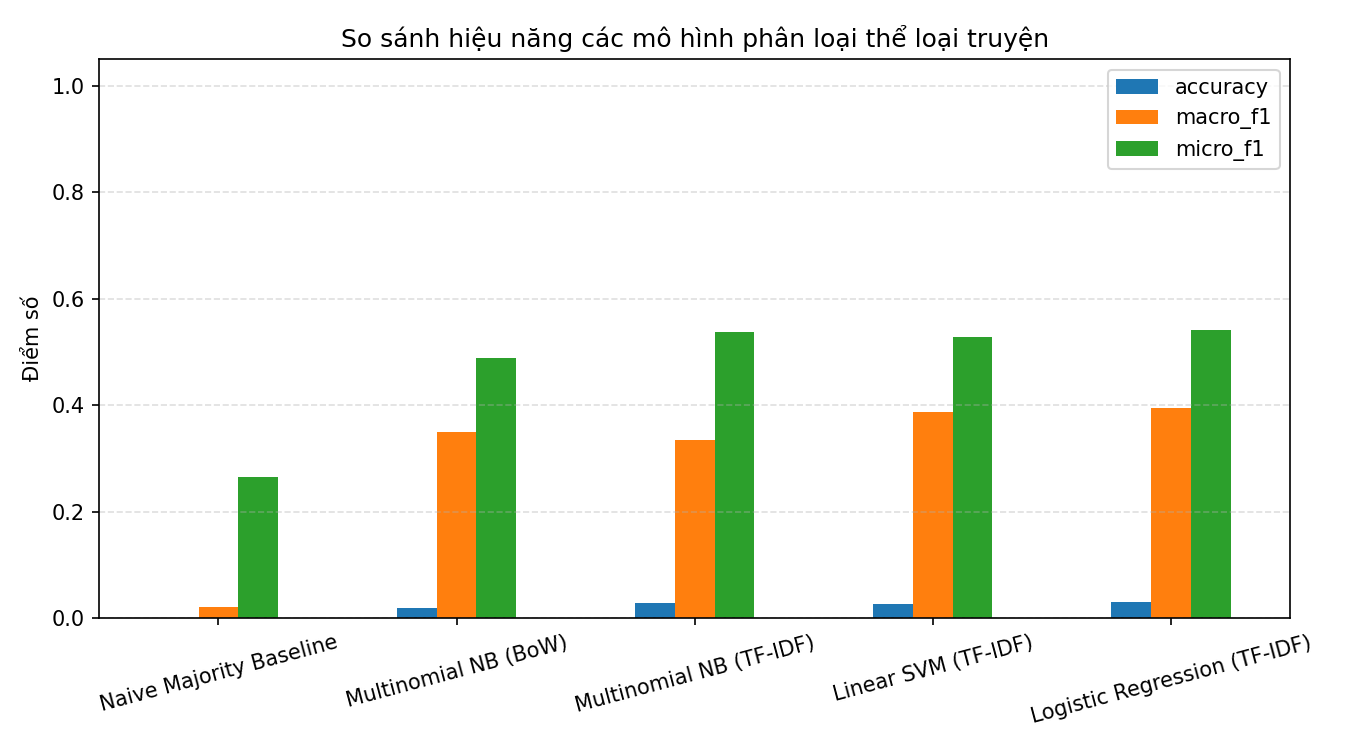

Đã lưu biểu đồ: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\ml_f1_per_label.png


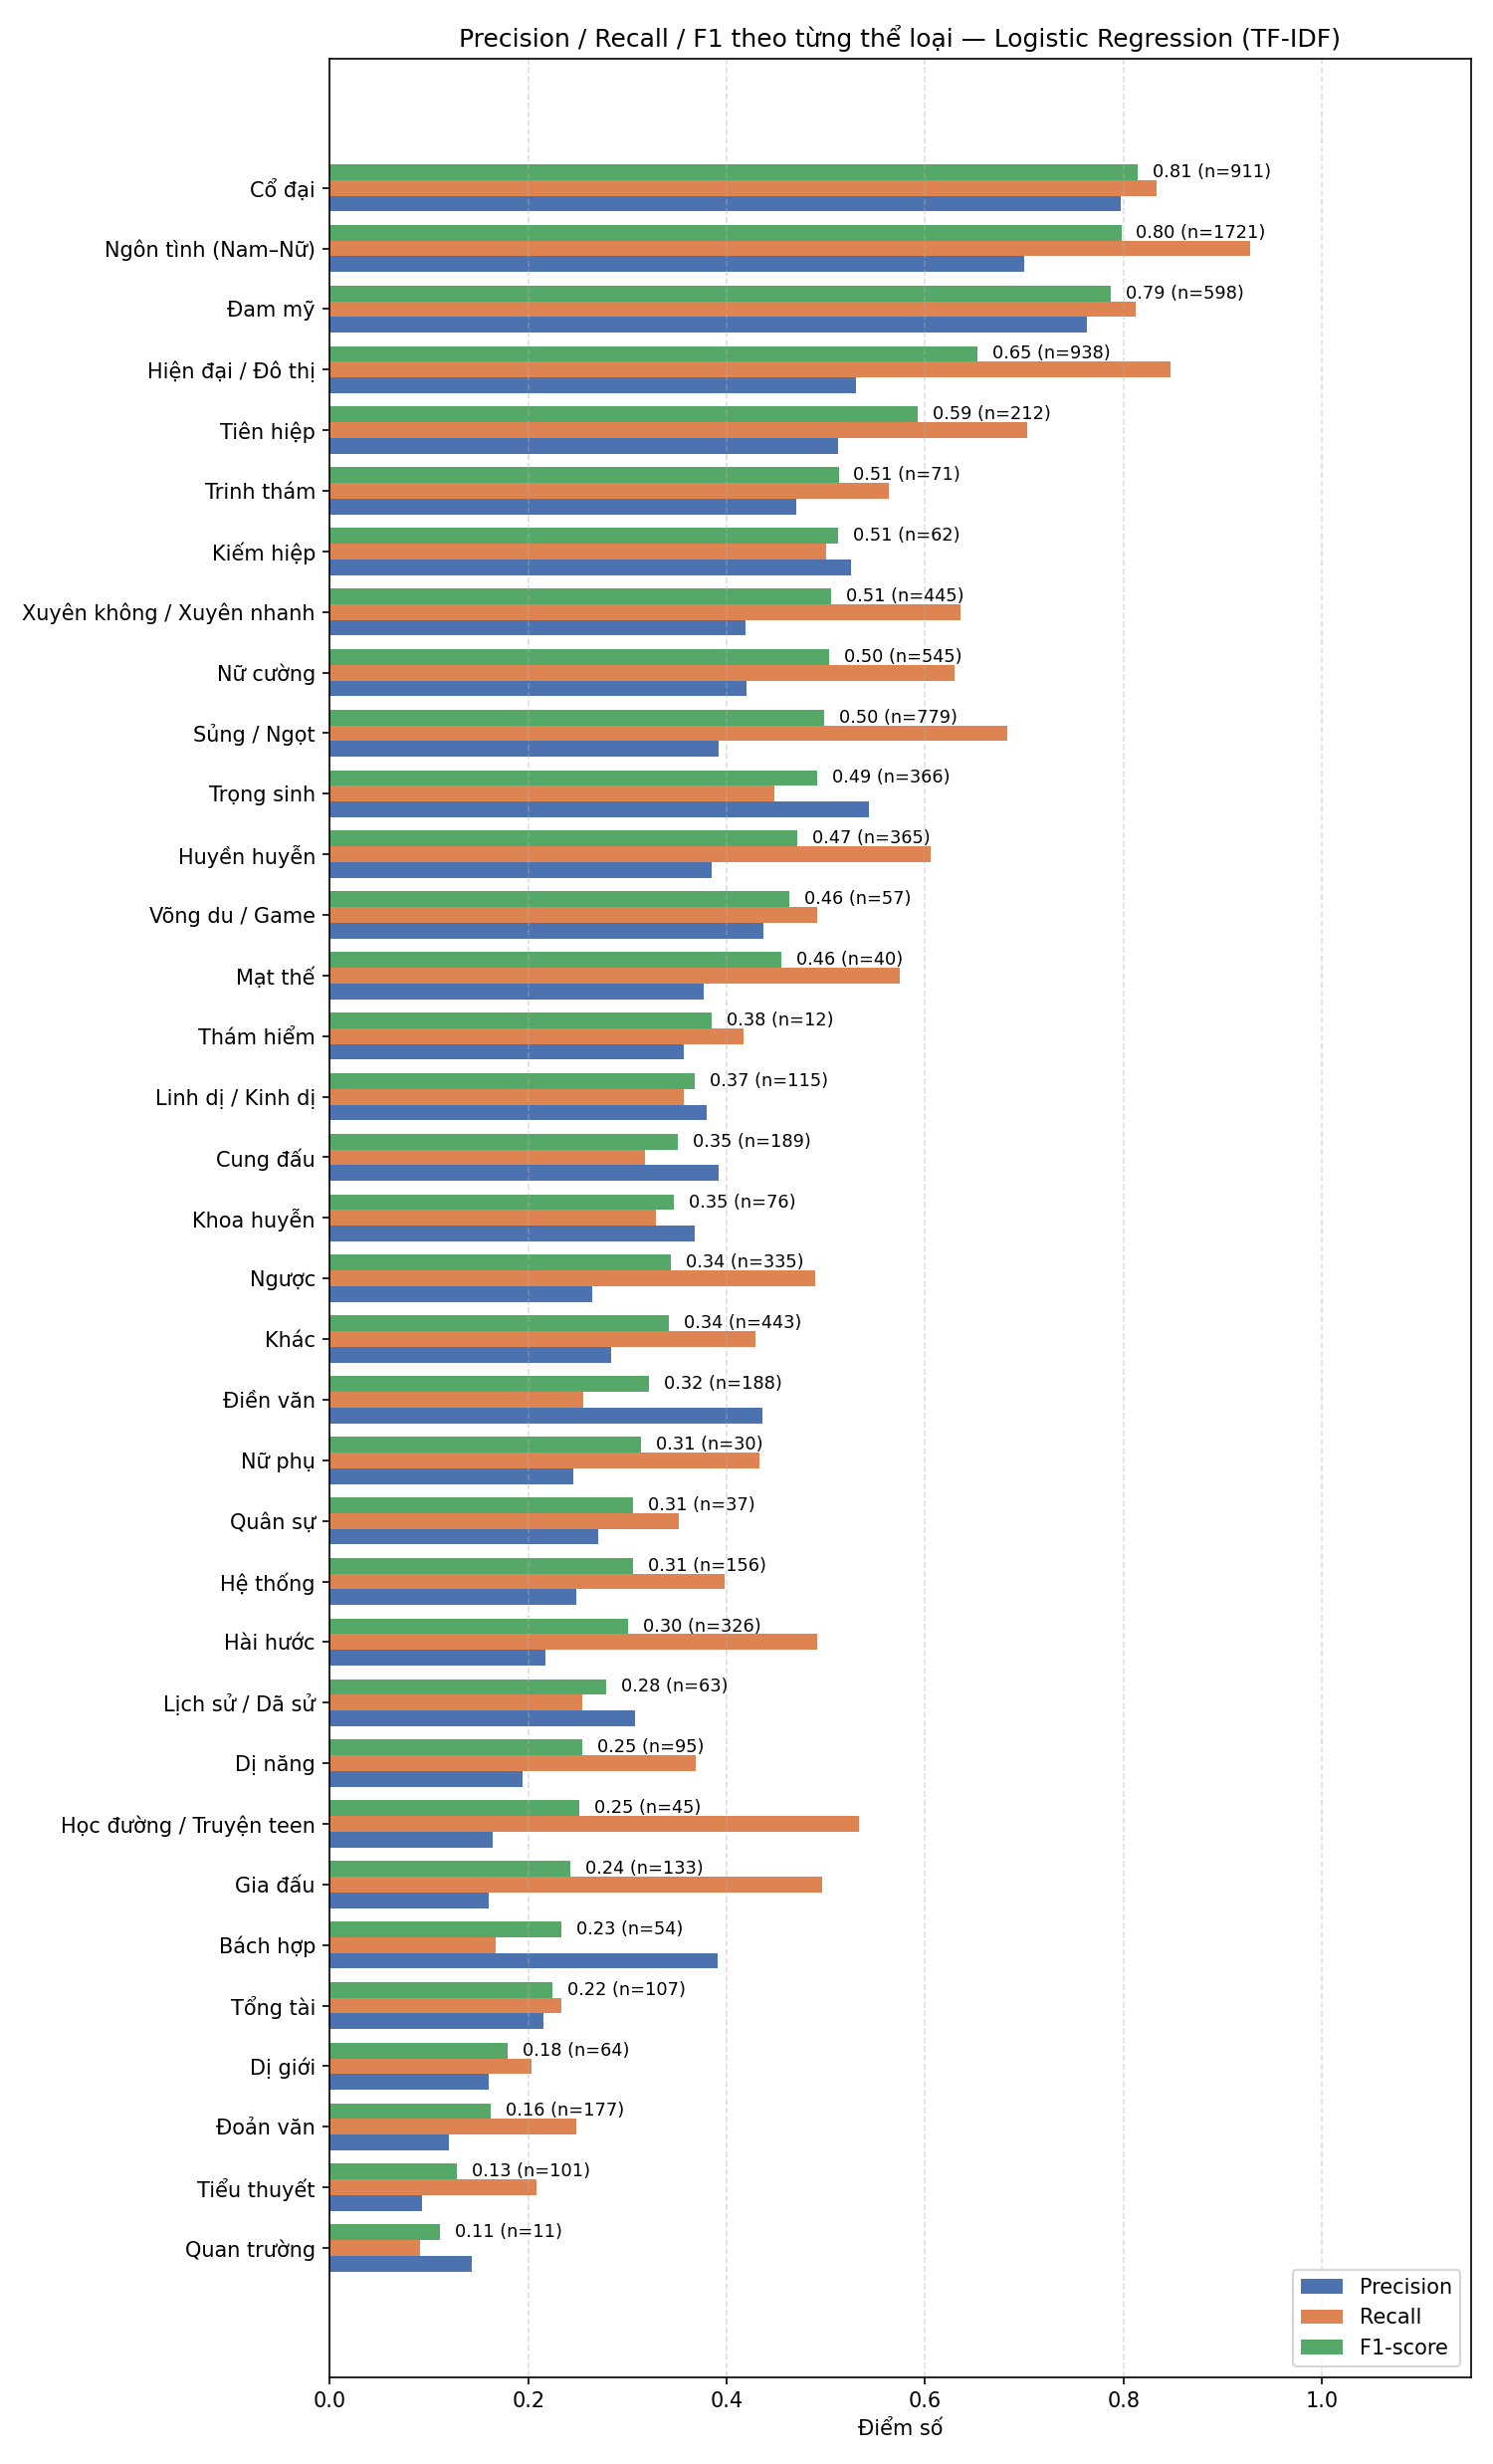

Đã lưu biểu đồ: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\ml_confusion_matrices.png


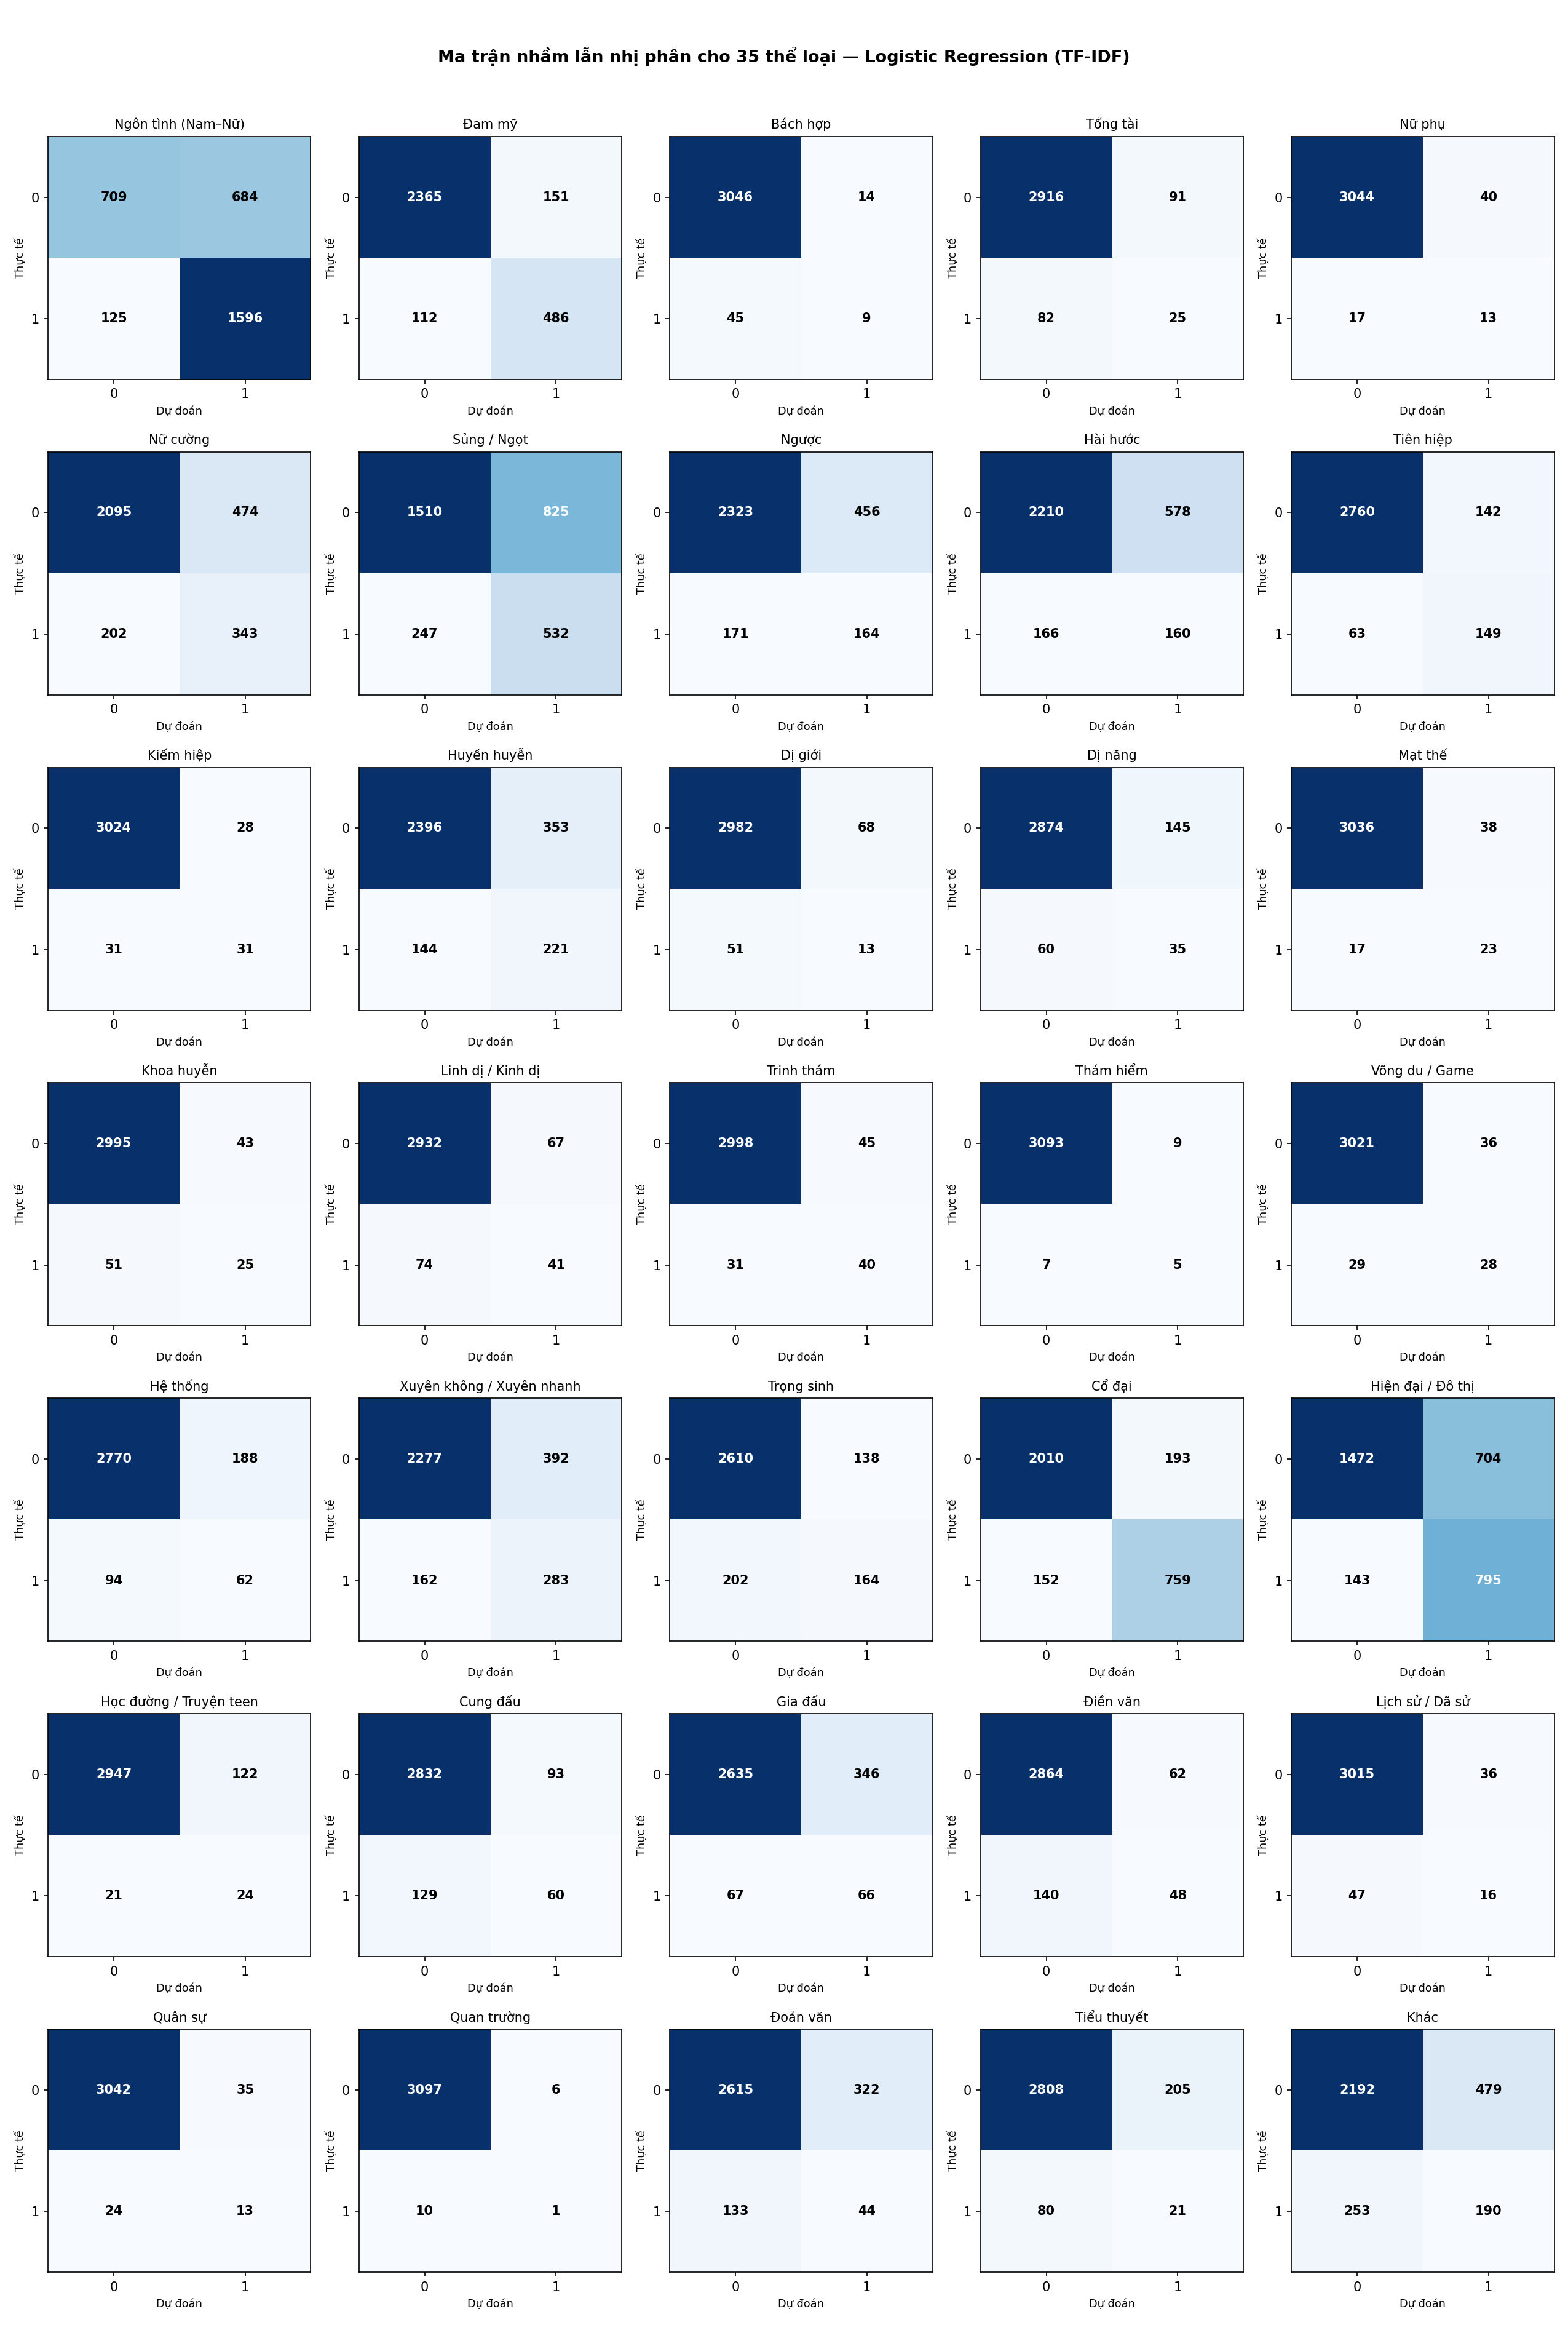

In [6]:
# Vẽ và lưu 3 biểu đồ đánh giá vào outputs/figures/, đồng thời hiển thị inline
from IPython.display import Image, display

fig_cmp = plot_model_comparison(
    test_summary_df.rename(columns={"model_name": "model_name"}),
    output_path=FIGURES_DIR / "ml_model_comparison.png",
)
fig_f1 = plot_f1_per_label(
    best_final_metrics["per_label"],
    label_names=GENRE_LABELS,
    model_name=best_entry["name"],
    output_path=FIGURES_DIR / "ml_f1_per_label.png",
)
fig_cm = plot_multilabel_confusion_matrices(
    best_final_metrics["confusion_matrices"],
    label_names=GENRE_LABELS,
    model_name=best_entry["name"],
    output_path=FIGURES_DIR / "ml_confusion_matrices.png",
)

for p in [fig_cmp, fig_f1, fig_cm]:
    if p is not None and p.exists():
        print("Đã lưu biểu đồ:", p)
        display(Image(filename=str(p)))

### Phân tích trực quan & Ma trận nhầm lẫn (`35` nhãn)
- Trên `Logistic Regression (TF-IDF)`, nhóm dẫn đầu gồm `co_dai` (`0.8148`), `ngon_tinh` (`0.7978`), `dam_my` (`0.7870`), `hien_dai` (`0.6524`), `tien_hiep` (`0.5924`), `trinh_tham` (`0.5128`), `kiem_hiep` (`0.5124`), `xuyen_khong` (`0.5054`), `nu_cuong` (`0.5037`); các thể loại đặc thù và nhóm được cào bổ sung như `mat_the` (`0.4554`), `tham_hiem` (`0.3846`), `khoa_huyen` (`0.3472`), `nu_phu` (`0.3133`), `quan_su` (`0.3059`) đều đạt kết quả khả quan.

Đã lưu ma trận cặp nhãn: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\error_confusion_pairs.png


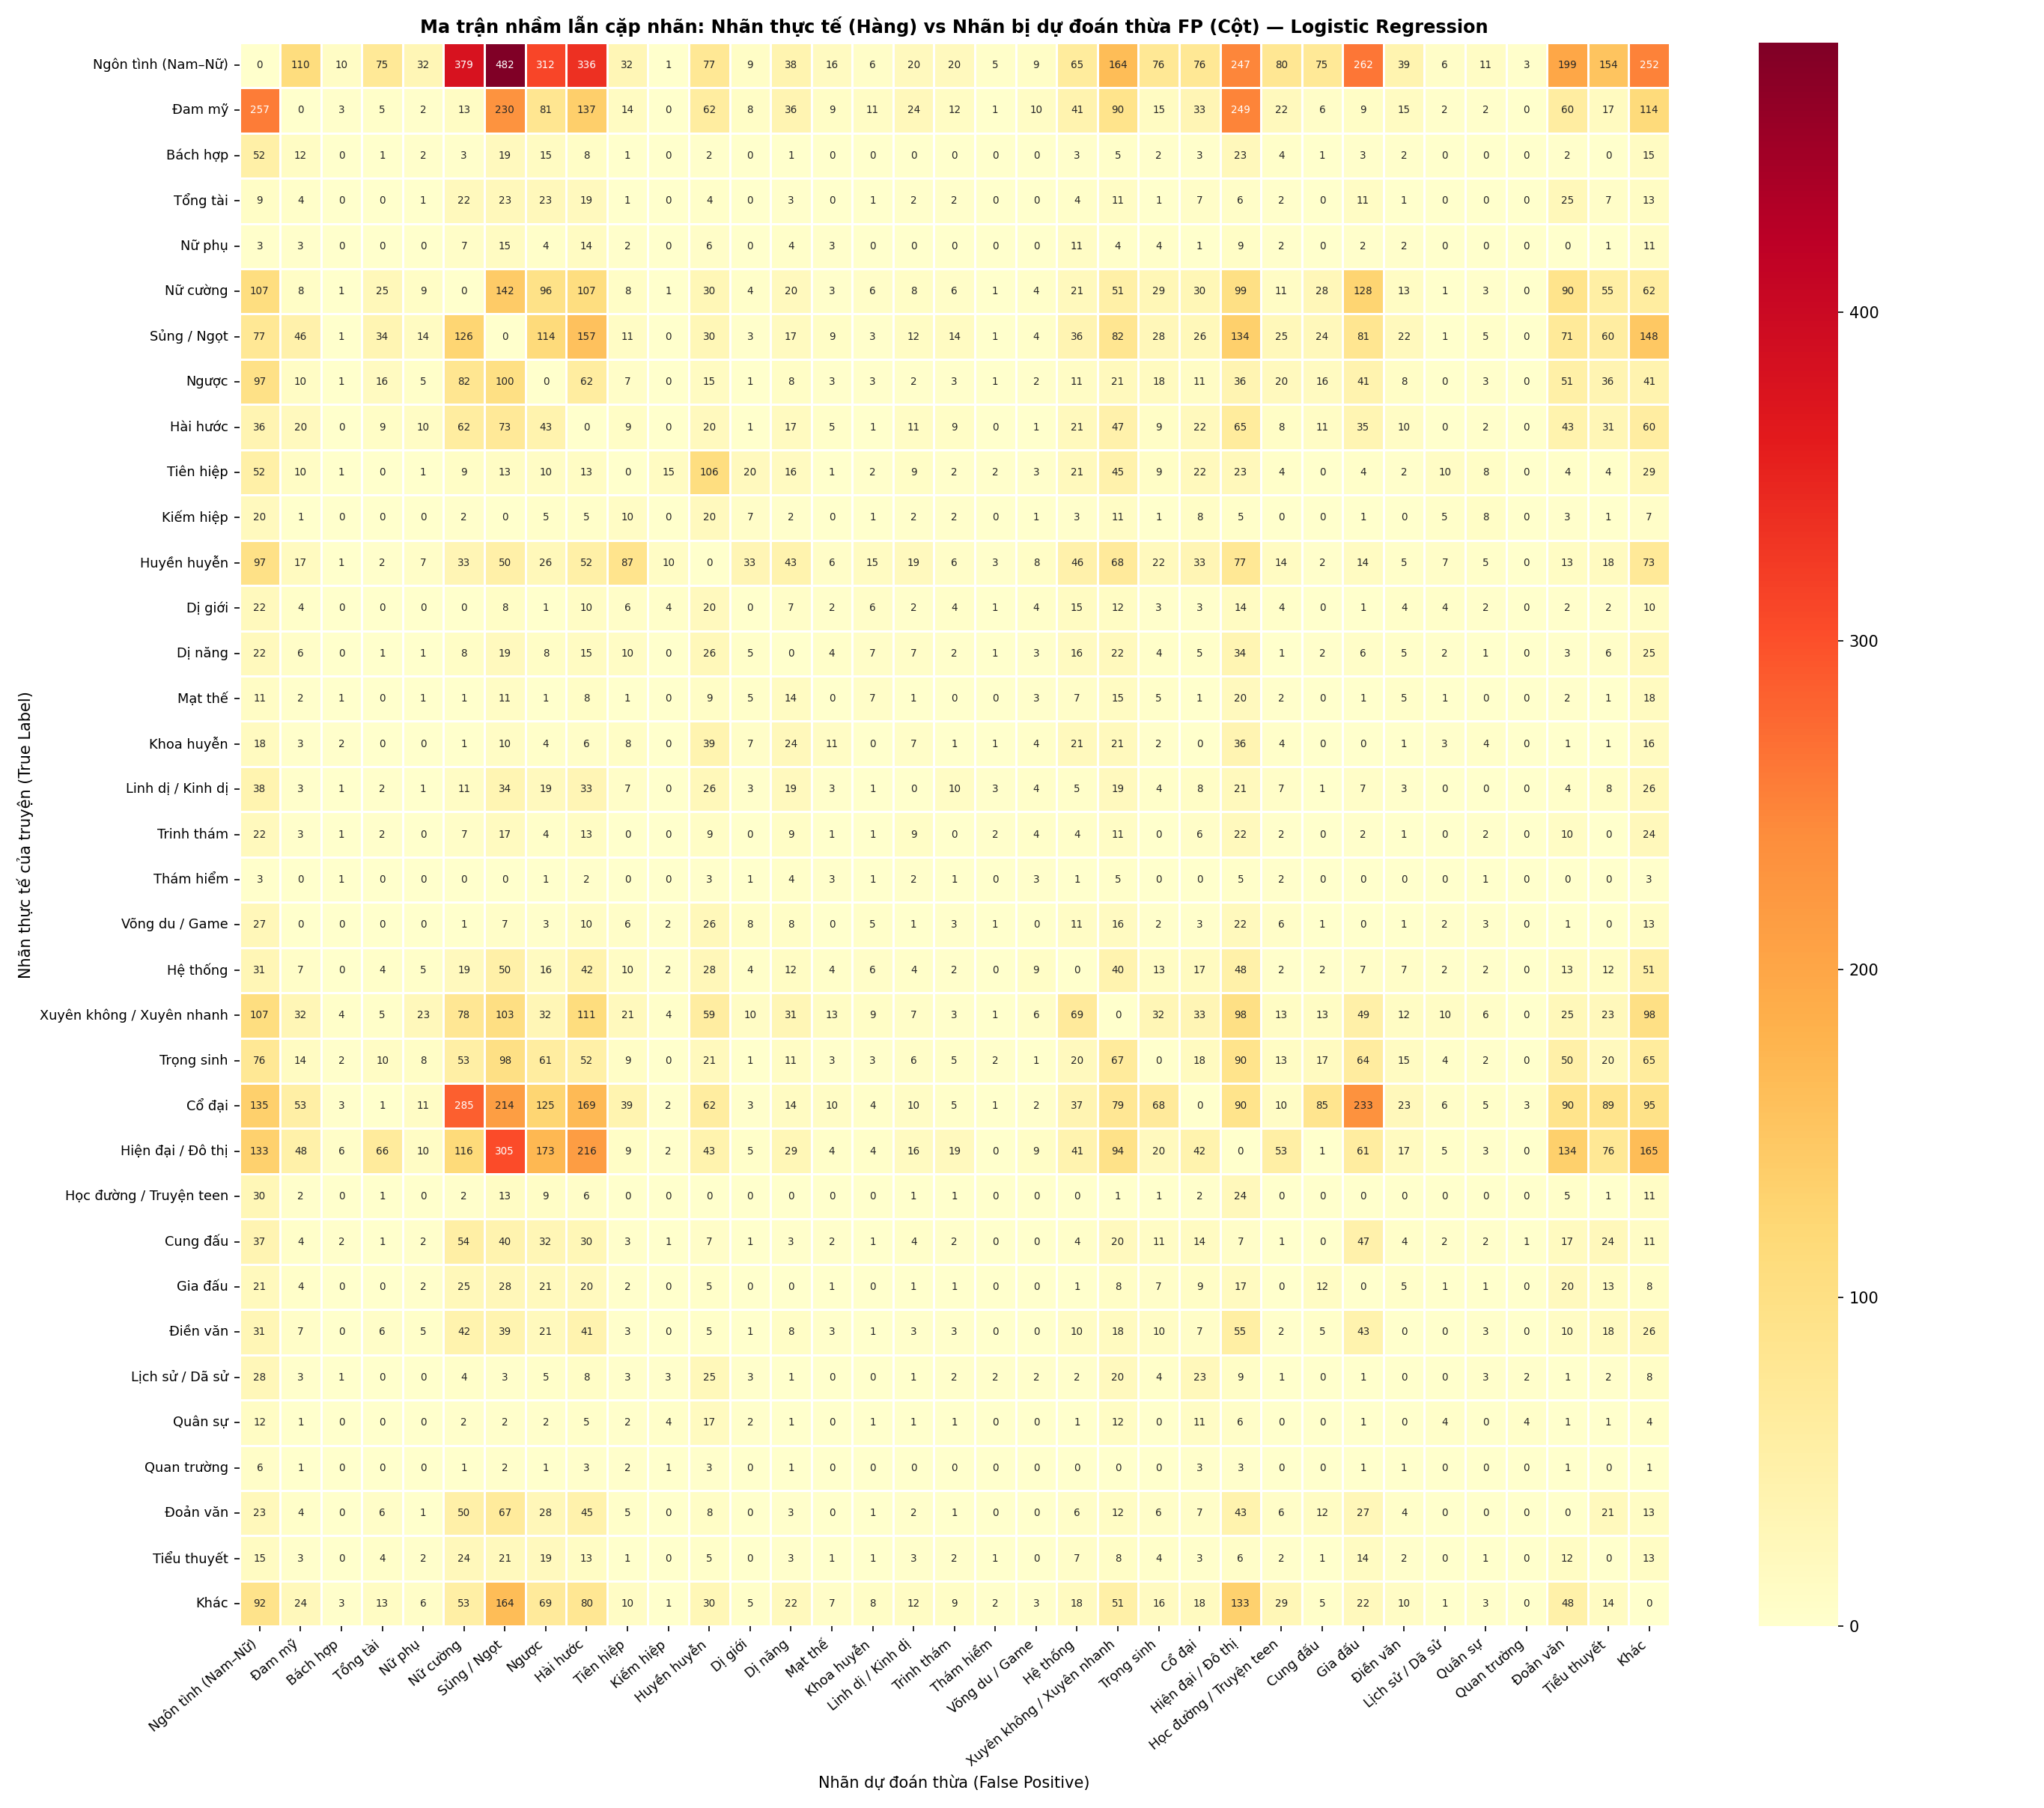

Tổng số mẫu thuộc 4 nhóm lỗi trọng tâm: 1187 | Đã lưu 12 mẫu đại diện tại C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\tables\error_cases_sample.csv


,id,title,source,error_group,true_genres,pred_genres,missing_fn,extra_fp
0,ST_0006,Vũ Thần Chúa Tể,webtruyen.vn,Thừa nhãn (trong_sinh / xuyen_khong),tien_hiep,tien_hiep|huyen_huyen|trong_sinh,,huyen_huyen|trong_sinh
1,ST_0010,Linh Vũ Thiên Hạ,webtruyen.vn,Nhầm cặp Tiên hiệp <-> Huyền huyễn,tien_hiep|xuyen_khong,tien_hiep|huyen_huyen|di_gioi|xuyen_khong|khac,,huyen_huyen|di_gioi|khac
2,ST_0014,Quang Âm Chi Ngoại,webnovel.vn,Thừa nhãn (trong_sinh / xuyen_khong),tien_hiep|huyen_huyen|khac,tien_hiep|huyen_huyen|di_gioi|di_nang|linh_di|...,khac,di_gioi|di_nang|linh_di|trinh_tham|tham_hiem|x...
3,ST_0022,Đại Phụng Đả Canh Nhân,webtruyen.vn,Thiếu nhãn ở truyện đa nhãn (>=4 nhãn),tien_hiep|kiem_hiep|huyen_huyen|di_gioi|linh_d...,ngon_tinh|huyen_huyen|di_nang|xuyen_khong,tien_hiep|kiem_hiep|di_gioi|linh_di|trinh_tham...,ngon_tinh|di_nang
4,ST_0026,Đấu Phá Thương Khung,webtruyen.vn,Nhầm cặp Tiên hiệp <-> Huyền huyễn,tien_hiep,ngon_tinh|tien_hiep|huyen_huyen|di_gioi,,ngon_tinh|huyen_huyen|di_gioi
5,ST_0038,Nhất Niệm Vĩnh Hằng,webtruyen.vn,Nhầm cặp Tiên hiệp <-> Huyền huyễn,hai_huoc|tien_hiep,hai_huoc|huyen_huyen|hien_dai|doan_van,tien_hiep,huyen_huyen|hien_dai|doan_van
6,ST_0046,Khánh Dư Niên,truyenfull.live,Thiếu nhãn ở truyện đa nhãn (>=4 nhãn),tien_hiep|xuyen_khong|co_dai|lich_su,ngon_tinh|dam_my|hai_huoc|xuyen_khong,tien_hiep|co_dai|lich_su,ngon_tinh|dam_my|hai_huoc
7,ST_0050,Siêu Thần Yêu Nghiệt,webtruyen.vn,Thừa nhãn (trong_sinh / xuyen_khong),hai_huoc|tien_hiep|huyen_huyen|trong_sinh|co_dai,tien_hiep|huyen_huyen|xuyen_khong,hai_huoc|trong_sinh|co_dai,xuyen_khong
8,ST_0054,Bất Hủ Phàm Nhân,webtruyen.vn,Thiếu nhãn ở truyện đa nhãn (>=4 nhãn),tien_hiep|huyen_huyen|di_gioi|xuyen_khong|tron...,dam_my|hai_huoc|tien_hiep|xuyen_khong,huyen_huyen|di_gioi|trong_sinh,dam_my|hai_huoc
9,ST_1226,Soán Đường,truyenfull.live,Nhầm cặp Cổ đại <-> Lịch sử,kiem_hiep|lich_su|quan_su,ngon_tinh|co_dai|khac,kiem_hiep|lich_su|quan_su,ngon_tinh|co_dai|khac


In [7]:
# Phân tích cặp nhãn nhầm lẫn (35x35) & Trích xuất 12 mẫu lỗi tiêu biểu (Logistic Regression)
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display
from src.config import TABLES_DIR

lr_entry = best_models["logistic_regression"]
lr_probs_test = predict_probabilities(lr_entry["model"], lr_entry["x_test"])
lr_thresh = (
    lr_entry["opt_thresholds"]
    if lr_entry["val_metrics_tuned"]["macro_f1"] >= lr_entry["val_metrics_default"]["macro_f1"]
    else 0.5
)
lr_pred = apply_thresholds(lr_probs_test, thresholds=lr_thresh, ensure_non_empty=True)

n_labels = len(GENRE_LABELS)
pair_matrix = np.zeros((n_labels, n_labels), dtype=int)
for r in range(len(y_test)):
    for i in range(n_labels):
        if y_test[r, i] == 1:
            for j in range(n_labels):
                if i != j and y_test[r, j] == 0 and lr_pred[r, j] == 1:
                    pair_matrix[i, j] += 1

disp_names = [GENRE_DISPLAY_NAMES[g] for g in GENRE_LABELS]
pair_df = pd.DataFrame(pair_matrix, index=disp_names, columns=disp_names)

fig, ax = plt.subplots(figsize=(max(14, 0.52 * n_labels), max(12, 0.46 * n_labels)))
sns.heatmap(pair_df, annot=True, fmt="d", cmap="YlOrRd", linewidths=0.5, annot_kws={"size": 6.5}, ax=ax)
ax.set_title("Ma trận nhầm lẫn cặp nhãn: Nhãn thực tế (Hàng) vs Nhãn bị dự đoán thừa FP (Cột) — Logistic Regression", fontsize=11.5, fontweight="bold")
ax.set_xlabel("Nhãn dự đoán thừa (False Positive)")
ax.set_ylabel("Nhãn thực tế của truyện (True Label)")
ax.tick_params(axis="both", labelsize=8.5)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
pair_fig_path = FIGURES_DIR / "error_confusion_pairs.png"
plt.savefig(pair_fig_path, dpi=150)
plt.close(fig)
print("Đã lưu ma trận cặp nhãn:", pair_fig_path)
display(Image(filename=str(pair_fig_path)))

case_records = []
for r in range(len(test_df)):
    true_set = [GENRE_LABELS[j] for j in range(n_labels) if y_test[r, j] == 1]
    pred_set = [GENRE_LABELS[j] for j in range(n_labels) if lr_pred[r, j] == 1]
    fp_set = [g for g in pred_set if g not in true_set]
    fn_set = [g for g in true_set if g not in pred_set]
    if not fp_set and not fn_set:
        continue

    if "trong_sinh" in fp_set or "xuyen_khong" in fp_set:
        cat = "Thừa nhãn (trong_sinh / xuyen_khong)"
    elif len(true_set) >= 4 and len(fn_set) >= 2:
        cat = "Thiếu nhãn ở truyện đa nhãn (>=4 nhãn)"
    elif ("tien_hiep" in fp_set and "huyen_huyen" in true_set) or ("huyen_huyen" in fp_set and "tien_hiep" in true_set):
        cat = "Nhầm cặp Tiên hiệp <-> Huyền huyễn"
    elif ("co_dai" in fp_set and "lich_su" in true_set) or ("lich_su" in fp_set and "co_dai" in true_set):
        cat = "Nhầm cặp Cổ đại <-> Lịch sử"
    else:
        continue

    case_records.append(
        {
            "id": test_df.loc[r, "id"],
            "title": test_df.loc[r, "title"],
            "source": test_df.loc[r, "source"],
            "error_group": cat,
            "true_genres": "|".join(true_set),
            "pred_genres": "|".join(pred_set),
            "missing_fn": "|".join(fn_set),
            "extra_fp": "|".join(fp_set),
            "summary_snippet": str(test_df.loc[r, "summary"])[:180],
        }
    )

cases_df = pd.DataFrame(case_records)
sample_cases_df = cases_df.groupby("error_group", group_keys=False).head(3).reset_index(drop=True)
cases_csv_path = TABLES_DIR / "error_cases_sample.csv"
sample_cases_df.to_csv(cases_csv_path, index=False, encoding="utf-8")
print(f"Tổng số mẫu thuộc 4 nhóm lỗi trọng tâm: {len(cases_df)} | Đã lưu {len(sample_cases_df)} mẫu đại diện tại {cases_csv_path}")
display(sample_cases_df[["id", "title", "source", "error_group", "true_genres", "pred_genres", "missing_fn", "extra_fp"]])

### Phân tích cặp nhãn nhầm lẫn `35×35` & Các mẫu lỗi tiêu biểu (Logistic Regression)
- Các cặp `False Positive` lớn nhất trên `Logistic Regression` gồm `ngon_tinh -> sung: 482`, `ngon_tinh -> nu_cuong: 379`, `ngon_tinh -> hai_huoc: 336`, `ngon_tinh -> nguoc: 312`, `hien_dai -> sung: 305` do giao thoa ngữ nghĩa mật thiết giữa các thẻ thuộc tính/phong cách tình cảm.
- Trích xuất được `1.187` mẫu thuộc 4 nhóm lỗi trọng tâm và lưu 12 mẫu đại diện vào `outputs/tables/error_cases_sample.csv`.

,label,ten_hien_thi,top_8_tu_vung
0,ngon_tinh,Ngôn tình (Nam–Nữ),"cô (14.20), nữ (5.80), đàn_ông (4.26), cậu ấy ..."
1,dam_my,Đam mỹ,"cậu (14.44), công (9.10), thụ (9.06), cp (5.58..."
2,bach_hop,Bách hợp,"nữ (6.38), phụ_nữ (5.72), nữ_nhân (5.62), ngưn..."
3,tong_tai,Tổng tài,"lạnh_lùng (5.66), sếp (4.61), bá_đạo (4.33), t..."
4,nu_phu,Nữ phụ,"nữ (10.59), cô (8.90), xuyên (7.82), tiểu_thuy..."
5,nu_cuong,Nữ cường,"nữ (5.39), khẽ (3.44), yêu phi (3.33), sinh_tồ..."
6,sung,Sủng / Ngọt,"sủng (8.49), ngọt (8.38), ngọt_ngào (4.03), sủ..."
7,nguoc,Ngược,"ngược (12.98), ngược_tâm (6.27), ngược_luyến (..."
8,hai_huoc,Hài hước,"hài (7.70), npc (3.66), tiện_thể (3.37), oan_g..."
9,tien_hiep,Tiên hiệp,"tu_tiên (11.39), tu_chân (6.82), tu (6.73), tô..."


Đã lưu biểu đồ top từ khóa: C:\Users\ACER\Downloads\NLP_CUỐI KỲ\outputs\figures\top_features_per_genre.png


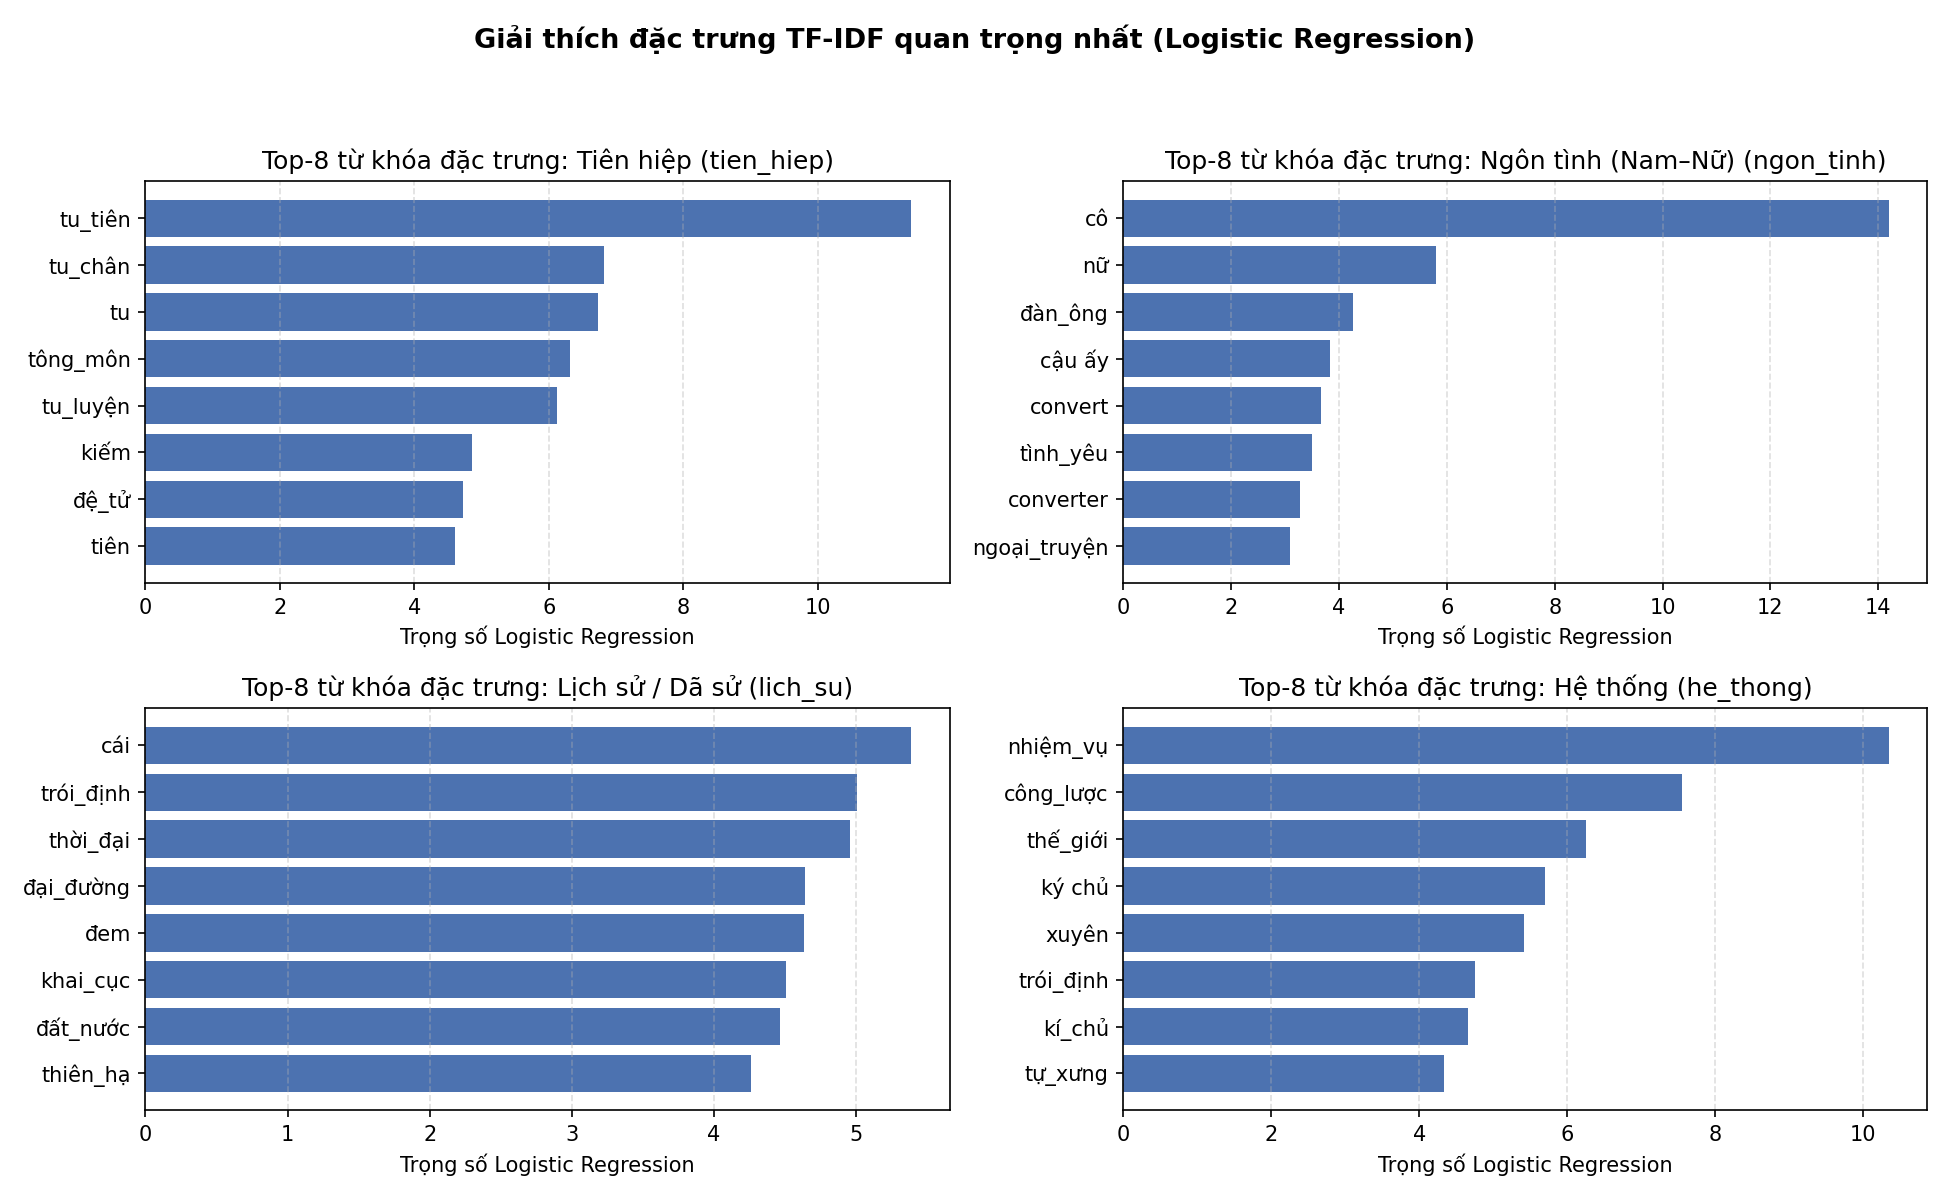

In [8]:
# Giải thích mô hình (Interpretability): Top-8 đặc trưng TF-IDF trọng số dương cao nhất từ Logistic Regression
feature_names = tfidf_vec.get_feature_names_out()
logreg_model = lr_entry["model"]
top_feat_rows = []
top_feat_dict = {}

for idx, lbl in enumerate(GENRE_LABELS):
    coefs = logreg_model.estimators_[idx].coef_[0]
    top_ids = np.argsort(coefs)[-8:][::-1]
    feats = [(str(feature_names[j]), round(float(coefs[j]), 3)) for j in top_ids]
    top_feat_dict[lbl] = feats
    top_feat_rows.append(
        {
            "label": lbl,
            "ten_hien_thi": GENRE_DISPLAY_NAMES[lbl],
            "top_8_tu_vung": ", ".join(f"{w} ({c:.2f})" for w, c in feats),
        }
    )

display(pd.DataFrame(top_feat_rows))

selected_4 = ["tien_hiep", "ngon_tinh", "lich_su", "he_thong"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, lbl in zip(axes.ravel(), selected_4):
    items = list(reversed(top_feat_dict[lbl]))
    words = [w for w, _ in items]
    weights = [c for _, c in items]
    ax.barh(words, weights, color="#4c72b0")
    ax.set_title(f"Top-8 từ khóa đặc trưng: {GENRE_DISPLAY_NAMES[lbl]} ({lbl})")
    ax.set_xlabel("Trọng số Logistic Regression")
    ax.grid(axis="x", linestyle="--", alpha=0.4)

fig.suptitle("Giải thích đặc trưng TF-IDF quan trọng nhất (Logistic Regression)", fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94])
feat_fig_path = FIGURES_DIR / "top_features_per_genre.png"
plt.savefig(feat_fig_path, dpi=150)
plt.close(fig)
print("Đã lưu biểu đồ top từ khóa:", feat_fig_path)
display(Image(filename=str(feat_fig_path)))

### Phân tích đặc trưng mô hình học được (Interpretability)
- Top từ khóa `coef_` của `Logistic Regression` chứng minh khả năng tách bạch đúng từ khóa đặc trưng cho 35 nhãn độc lập: `tham_hiem` (*phiêu_lưu, vùng_đất, hành_trình*), `mat_the` (*tận thế, zombie, tang_thi*), `khoa_huyen` (*thế_giới, vũ_trụ, viễn_tưởng*), `di_nang` (*không_gian, năng_lực, biến_dị*), `vong_du` (*game, trò_chơi, online*), `trinh_tham` (*cảnh_sát, phá_án, tội_phạm*), `linh_di` (*quỷ, thần_quái, ma*), `cung_dau` (*cung_đình, hoàng_hậu, thái_tử*), `gia_dau` (*hầu_phủ, phu_quân*), `quan_su` (*chiến_tranh, quân_đội*), `quan_truong` (*cán_bộ, triều_đình, chính_trị*).

## Tổng kết Giai đoạn 5a (ML Baselines & Giải thích mô hình)
- Trên bộ **35 nhãn chuẩn** (`20.852` truyện), **`Logistic Regression (C=2.0, cw=balanced)`** dẫn đầu nhóm ML về **Accuracy (`0.0302`)**, **Macro-F1 (`0.3944`)** và **Micro-F1 (`0.5413`)** (`Hamming = 0.1008`), vượt gần 20 lần Naive Baseline (`Macro-F1 = 0.0203`), trong khi **`Multinomial NB (TF-IDF)`** đạt **Hamming Loss thấp nhất (`0.0947`)**.
- Đã phân tích ma trận cặp nhãn `35×35` (`error_confusion_pairs.png`), xuất 12 mẫu lỗi trọng tâm (`error_cases_sample.csv`) và giải thích top-8 từ khóa `coef_` (`top_features_per_genre.png`) phục vụ báo cáo TV3.